# Phase 1: Swin-T Fine-tuning — Task A (Balanced)

**Task**: Conifer Family Classification (Task A — Family-level, 4 classes)

**Dataset**: `data/task-A/` — balanced augmented dataset from Phase 0.
Podocarpaceae & Taxaceae đã được augment từ ~217/206 lên 1,600 mẫu mỗi lớp.
Train split: 7,264 mẫu (vs 4,487 imbalanced trước đó).

**Fine-tuning Strategy** (per WoodID_plan.md):
- Backbone LR = 1e-5, Head LR = 1e-4 (differential LR)
- 50 epochs, cosine annealing + 5-epoch linear warmup
- Label smoothing 0.1, AMP enabled
- All checkpoints saved (`save_best_only=False`) để track convergence

**Output**: Checkpoints & metrics saved to `~/experiments/woodbench/task-A/`

---

## Contents

1. [Setup & Root Detection](#1-setup)
2. [Download Dataset from HuggingFace](#2-download)
3. [Verify Dataset Distribution](#3-verify)
4. [Create Dataloaders](#4-dataloaders)
5. [Create & Test Model](#5-model)
6. [Training Configuration](#6-config)
7. [Fine-tune Swin-T](#7-train)
8. [Evaluate on Test Set](#8-evaluate)
9. [Summary](#9-summary)

## 1. Setup & Root Detection <a id='1-setup'></a>

Detects project root from notebook location. Notebook chạy trên SSH server.
Tìm ROOT bằng cách walk upward từ CWD cho đến khi thấy `src/` + `pyproject.toml`.

In [1]:
from pathlib import Path
import sys

# Find project root: walk upward looking for src/ + pyproject.toml
# Works regardless of which directory the notebook kernel was started from
cwd = Path.cwd()
ROOT = cwd
for parent in [cwd, *cwd.parents]:
    if (parent / "src").is_dir() and (parent / "pyproject.toml").exists():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

import torch
print(f"[ROOT] {ROOT}")
print(f"[CWD]  {cwd}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

[ROOT] /workspace/woodbench
[CWD]  /workspace/woodbench/notebooks/phase 1
PyTorch: 2.11.0+cu128
CUDA: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 16.7 GB


## 2. Download Dataset from HuggingFace <a id='2-download'></a>

Dataset được lưu trên HuggingFace Hub. Download một lần — sau đó dùng local.
Nếu dataset đã tồn tại, bước này skip.

In [2]:
DATA_DIR = ROOT / "data" / "task-A"
HF_TASK_A_REPO = "ny0g507h3p/wood-task-A"

if DATA_DIR.exists() and (DATA_DIR / "train").exists():
    train_imgs = (
        sum(1 for f in (DATA_DIR / "train").rglob("*.png")) +
        sum(1 for f in (DATA_DIR / "train").rglob("*.jpg"))
    )
    print(f"[OK] Dataset found at {DATA_DIR}")
    print(f"     Train images: {train_imgs}")
    if train_imgs >= 7000:
        print("     Status: BALANCED (~7,264 expected)")
    else:
        print("     WARNING: Expected ~7,264 train images")
else:
    print(f"[WARN] Dataset not found at {DATA_DIR}")
    print("Downloading from HuggingFace...")
    from huggingface_hub import snapshot_download
    import os
    hf_token = os.environ.get("HF_TOKEN", "")
    snapshot_download(
        repo_id=HF_TASK_A_REPO,
        repo_type="dataset",
        local_dir=str(DATA_DIR),
        token=hf_token or None,
    )
    print(f"[OK] Downloaded to {DATA_DIR}")

[OK] Dataset found at /workspace/woodbench/data/task-A
     Train images: 7264
     Status: BALANCED (~7,264 expected)


## 3. Verify Dataset Distribution <a id='3-verify'></a>

Expected distribution (balanced):
- Cupressaceae: ~2,398 (majority, unchanged)
- Pinaceae: ~1,666 (majority, unchanged)
- Podocarpaceae: ~1,600 (minority, augmented from 217)
- Taxaceae: ~1,600 (minority, augmented from 206)
- Total train: 7,264

In [3]:
from src.data import ConiferDataset

train_ds = ConiferDataset(DATA_DIR, split="train", task="taskA")
print(f"Total training samples: {len(train_ds)}")
print(f"Classes: {train_ds.classes}")
print()
print("Class distribution:")
for family, count in train_ds.get_class_distribution().items():
    pct = count / len(train_ds) * 100
    print(f"  {family}: {count} ({pct:.1f}%)")

expected = 2398 + 1666 + 1600 + 1600
total = len(train_ds)
print()
print(f"Expected: {expected}")
print(f"Actual:   {total}")
print(f"Match:    {'OK' if total == expected else 'CHECK DATA'}")

Total training samples: 7264
Classes: ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae']

Class distribution:
  Cupressaceae: 2398 (33.0%)
  Pinaceae: 1666 (22.9%)
  Podocarpaceae: 1600 (22.0%)
  Taxaceae: 1600 (22.0%)

Expected: 7264
Actual:   7264
Match:    OK


## 4. Create Dataloaders <a id='4-dataloaders'></a>

Train: shuffle=True, drop_last=True, persistent_workers.
`use_90rotation=False` cho baseline — ablation variant ở Phase 3.

In [4]:
from src.data import get_dataloaders

BATCH_SIZE = 64
IMG_SIZE = 224
NUM_WORKERS = 4
USE_90ROTATION = False

train_loader, val_loader, test_loader = get_dataloaders(
    data_root=DATA_DIR,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    img_size=IMG_SIZE,
    use_90rotation=USE_90ROTATION,
)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")
print(f"Test batches:  {len(test_loader)}")

images, labels = next(iter(train_loader))
print(f"\nBatch shape: {images.shape}")
print(f"Labels shape: {labels.shape}")

Train batches: 113
Val batches:   15
Test batches:  16



Batch shape: torch.Size([64, 3, 224, 224])
Labels shape: torch.Size([64])


## 5. Create & Test Model <a id='5-model'></a>

Swin-T (swin_tiny_patch4_window7_224): ~28M params, unfrozen backbone (fine-tuning mode).
Differential learning rates được áp dụng trong optimizer.

In [5]:
from src.models import create_model, BACKBONE_NAMES

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

print("\nAvailable backbones:")
for name, timm_name in BACKBONE_NAMES.items():
    print(f"  {name}: {timm_name}")

# Swin-T — unfrozen backbone = fine-tuning
model = create_model("swin_tiny", num_classes=4, pretrained=True, freeze_backbone=False)
model = model.to(device)

# Test forward pass
outputs = model(images.to(device))
print(f"\nOutput shape: {outputs.shape}  (expected: ({images.shape[0]}, 4))")

# Count parameters
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"\nTotal params:   {total / 1e6:.2f}M")
print(f"Trainable:     {trainable / 1e6:.2f}M")
print(f"Frozen:        {frozen / 1e6:.2f}M")
print(f"Mode:          {'UNFROZEN (fine-tune)' if frozen == 0 else 'PARTIALLY FROZEN'}")

Device: cuda

Available backbones:
  resnet50: resnet50
  efficientnet_b3: tf_efficientnet_b3
  mobilenetv3_large: mobilenetv3_large_100
  convnext_tiny: convnext_tiny
  swin_tiny: swin_tiny_patch4_window7_224



Output shape: torch.Size([64, 4])  (expected: (64, 4))

Total params:   27.52M
Trainable:     27.52M
Frozen:        0.00M
Mode:          UNFROZEN (fine-tune)


## 6. Training Configuration <a id='6-config'></a>

Đặt tất cả hyperparameters ở đây để dễ thay đổi.

In [6]:
from pathlib import Path
from src.train import TrainingEngine, create_optimizer, create_scheduler, create_loss_function
from src.utils import set_seed

# === Hyperparameters ===
EPOCHS = 50
HEAD_LR = 1e-4
BACKBONE_LR = 1e-5
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
SCHEDULER_TYPE = "cosine"
WARMUP_EPOCHS = 5
SEED = 42
USE_AMP = True
SAVE_BEST_ONLY = False  # Save every epoch to track convergence

# === Output directory ===
EXP_DIR = ROOT / "data" / "experiments" / "swin_tiny"
EXP_DIR.mkdir(parents=True, exist_ok=True)
print(f"[Output] {EXP_DIR}")

# === Reproducibility ===
set_seed(SEED)

# === Re-create model from pretrained weights ===
model = create_model("swin_tiny", num_classes=4, pretrained=True, freeze_backbone=False)
model = model.to(device)

# === Optimizer with differential LR ===
optimizer = create_optimizer(
    model,
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY,
    backbone_lr=BACKBONE_LR,
)

print("Optimizer param groups:")
for pg in optimizer.param_groups:
    print(f"  [{pg['name']}] lr={pg['lr']:.2e}, {len(pg['params'])} tensors")

# === Scheduler ===
scheduler = create_scheduler(
    optimizer,
    epochs=EPOCHS,
    scheduler_type=SCHEDULER_TYPE,
    warmup_epochs=WARMUP_EPOCHS,
)

# === Loss function ===
criterion = create_loss_function(loss_type="label_smoothing", label_smoothing=LABEL_SMOOTHING)

# === Training engine ===
engine = TrainingEngine(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    criterion=criterion,
    device=device,
    use_amp=USE_AMP,
)

# === Summary ===
print()
print("Training config:")
print(f"  Backbone:      Swin-T (unfrozen)")
print(f"  Epochs:        {EPOCHS}")
print(f"  Head LR:       {HEAD_LR}")
print(f"  Backbone LR:   {BACKBONE_LR}")
print(f"  Weight decay:  {WEIGHT_DECAY}")
print(f"  Label smooth:  {LABEL_SMOOTHING}")
print(f"  Scheduler:     {SCHEDULER_TYPE} + {WARMUP_EPOCHS}-epoch warmup")
print(f"  AMP:           {USE_AMP}")
print(f"  Seed:          {SEED}")
print(f"  Train samples: {len(train_ds)}")

[Output] /workspace/woodbench/data/experiments/swin_tiny


Optimizer param groups:
  [head] lr=1.00e-04, 50 tensors
  [backbone] lr=1.00e-05, 123 tensors

Training config:
  Backbone:      Swin-T (unfrozen)
  Epochs:        50
  Head LR:       0.0001
  Backbone LR:   1e-05
  Weight decay:  0.0001
  Label smooth:  0.1
  Scheduler:     cosine + 5-epoch warmup
  AMP:           True
  Seed:          42
  Train samples: 7264


## 7. Fine-tune Swin-T <a id='7-train'></a>

Training loop: train → validate → save checkpoint mỗi epoch.
`save_best_only=False` để lưu checkpoint mọi epoch — track được convergence curve.
Checkpoints được lưu tại `EXP_DIR`: `{name}_epochN.pth`, `{name}_best.pth`, `{name}_last.pth`.

In [ ]:
results = engine.fit(
    epochs=EPOCHS,
    output_dir=EXP_DIR,
    name="swin_tiny",
    save_best_only=SAVE_BEST_ONLY,
    verbose=True,
)

print()
print(f"Best val accuracy: {results['best_val_acc']:.2f}% (epoch {results['best_epoch']})")
print(f"Final train acc:  {results['final_train_acc']:.2f}%")
print(f"Final val acc:    {results['final_val_acc']:.2f}%")

In [7]:
# List all checkpoints saved during training
epoch_ckpts = sorted(EXP_DIR.glob("swin_tiny_epoch*.pth"))
best_ckpt = EXP_DIR / "swin_tiny_best.pth"
last_ckpt = EXP_DIR / "swin_tiny_last.pth"

print(f"Epoch checkpoints: {len(epoch_ckpts)}")
print(f"Best checkpoint:   {best_ckpt.name}  ({best_ckpt.exists()})")
print(f"Last checkpoint:   {last_ckpt.name}  ({last_ckpt.exists()})")

# Load best checkpoint
if best_ckpt.exists():
    ckpt = torch.load(best_ckpt, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"\nLoaded best: epoch {ckpt.get('epoch', 0)+1}, val_acc={ckpt.get('best_val_acc', 0):.2f}%")

Epoch checkpoints: 10
Best checkpoint:   swin_tiny_best.pth  (True)
Last checkpoint:   swin_tiny_last.pth  (False)

Loaded best: epoch 5, val_acc=100.00%


## 8. Evaluate on Test Set <a id='8-evaluate'></a>

Đánh giá trên test set (không augment) với best checkpoint.

In [8]:
from src.eval import compute_metrics, format_metrics, save_confusion_matrix

CLASS_NAMES = ["Cupressaceae", "Pinaceae", "Podocarpaceae", "Taxaceae"]

model.eval()
metrics = compute_metrics(
    model=model,
    data_loader=test_loader,
    device=device,
    num_classes=4,
    class_names=CLASS_NAMES,
)

print(format_metrics(metrics, CLASS_NAMES))

EVALUATION RESULTS
Accuracy:      99.69%
Precision:     99.34%
Recall:        99.35%
F1-macro:      99.34%

Per-Class F1 Scores:
  Cupressaceae        : 99.81%
  Pinaceae            : 99.73%
  Podocarpaceae       : 98.95%
  Taxaceae            : 98.88%


In [9]:
# Save confusion matrix
cm_path = EXP_DIR / "confusion_matrix.png"
save_confusion_matrix(
    cm=metrics["confusion_matrix"],
    class_names=CLASS_NAMES,
    output_path=cm_path,
    title="Swin-T — Task A (Test Set)",
)
print(f"Confusion matrix saved: {cm_path}")

# Per-class accuracy from confusion matrix
print()
print("Per-class accuracy:")
cm = metrics["confusion_matrix"]
for i, name in enumerate(CLASS_NAMES):
    correct = cm[i, i]
    total = cm[i, :].sum()
    acc = correct / total * 100 if total > 0 else 0
    print(f"  {name}: {correct}/{total} = {acc:.1f}%")

Confusion matrix saved: /workspace/woodbench/data/experiments/swin_tiny/confusion_matrix.png

Per-class accuracy:
  Cupressaceae: 523/525 = 99.6%
  Pinaceae: 364/364 = 100.0%
  Podocarpaceae: 47/47 = 100.0%
  Taxaceae: 44/45 = 97.8%


Per-class F1 chart saved: /workspace/woodbench/data/experiments/swin_tiny/per_class_f1.png


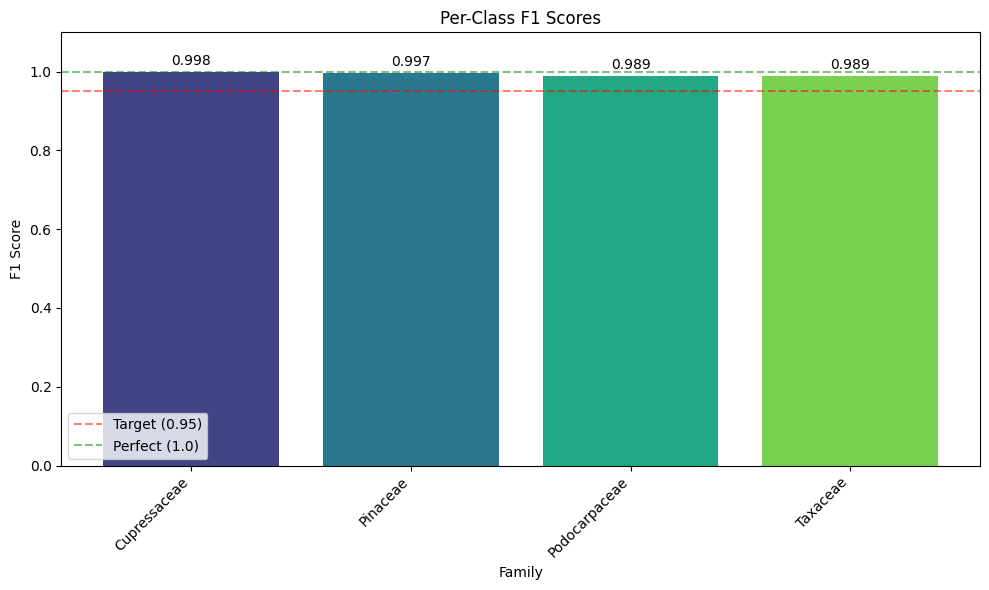

In [10]:
# Per-class F1 bar chart
from src.eval.confusion import plot_per_class_f1

f1_path = EXP_DIR / "per_class_f1.png"
plot_per_class_f1(
    per_class_metrics=metrics["per_class"],
    class_names=CLASS_NAMES,
    output_path=f1_path,
)
print(f"Per-class F1 chart saved: {f1_path}")

In [11]:
# Measure inference time (GPU only)
if device == "cuda":
    from src.eval.metrics import measure_inference_time

    timing = measure_inference_time(
        model=model,
        device=device,
        num_runs=100,
        warmup_runs=10,
        batch_size=1,
    )
    print(f"Inference time (batch=1):")
    print(f"  Mean:   {timing['mean_ms']:.3f} ms/batch")
    print(f"  Per image: {timing['per_image_ms']:.3f} ms/image")
    print(f"  Std:    {timing['std_ms']:.3f} ms")
    print(f"  Min:    {timing['min_ms']:.3f} ms")
    print(f"  Max:    {timing['max_ms']:.3f} ms")

    import json
    timing_path = EXP_DIR / "inference_time.json"
    with open(timing_path, "w") as f:
        json.dump(timing, f, indent=2)
    print(f"Timing saved: {timing_path}")
else:
    print("Inference time: skipped (no GPU)")

Inference time (batch=1):
  Mean:   9.896 ms/batch
  Per image: 9.896 ms/image
  Std:    0.239 ms
  Min:    9.349 ms
  Max:    10.173 ms
Timing saved: /workspace/woodbench/data/experiments/swin_tiny/inference_time.json


## 9. Summary <a id='9-summary'></a>

In [13]:
# Final results summary
import json
from pathlib import Path

summary_path = EXP_DIR / "results_summary.json"
timing_path = EXP_DIR / "inference_time.json"

# Prefer live notebook variables when available, but fall back to saved artifacts
results_data = globals().get("results")
if results_data is None and summary_path.exists():
    with open(summary_path, "r") as f:
        results_data = json.load(f)

if results_data is None:
    raise RuntimeError(
        f"No training summary found. Run the training and evaluation cells first, or check {summary_path}."
    )

metrics_data = globals().get("metrics")
if metrics_data is None:
    metrics_data = {}

timing_data = globals().get("timing")
if timing_data is None and timing_path.exists():
    with open(timing_path, "r") as f:
        timing_data = json.load(f)
if timing_data is None:
    timing_data = {}

print("=" * 50)
print("SWIN-T — TASK A RESULTS")
print("=" * 50)
print(f"Best val accuracy:  {results_data['best_val_acc']:.2f}% (epoch {results_data['best_epoch']})")
print(f"Test accuracy:      {results_data.get('test_accuracy', metrics_data.get('accuracy', 0.0)) * 100:.2f}%")
print(f"Test F1-macro:     {results_data.get('test_f1_macro', metrics_data.get('f1_macro', 0.0)) * 100:.2f}%")
if timing_data:
    print(f"Inference (ms/img): {timing_data.get('per_image_ms', results_data.get('inference_ms_per_image', 0.0)):.3f}")
print(f"Output directory:   {EXP_DIR}")
print()
print("Per-class F1:")
per_class_f1 = results_data.get("per_class_f1")
if per_class_f1 is None and metrics_data.get("per_class"):
    per_class_f1 = {name: scores["f1"] for name, scores in metrics_data["per_class"].items()}

if per_class_f1:
    for name, score in per_class_f1.items():
        print(f"  {name}: {score * 100:.2f}%")
else:
    print("  Unavailable")

# Save results
results_summary = {
    "backbone": "swin_tiny",
    "task": "Task A (Family Classification)",
    "epochs": EPOCHS,
    "seed": SEED,
    "best_val_acc": results_data["best_val_acc"],
    "best_epoch": results_data["best_epoch"],
    "test_accuracy": float(results_data.get("test_accuracy", metrics_data.get("accuracy", 0.0))),
    "test_f1_macro": float(results_data.get("test_f1_macro", metrics_data.get("f1_macro", 0.0))),
    "test_precision": float(results_data.get("test_precision", metrics_data.get("precision_macro", 0.0))),
    "test_recall": float(results_data.get("test_recall", metrics_data.get("recall_macro", 0.0))),
    "per_class_f1": per_class_f1 or {},
    "inference_ms_per_image": timing_data.get("per_image_ms", results_data.get("inference_ms_per_image")),
    "train_samples": len(train_ds),
    "batch_size": BATCH_SIZE,
    "head_lr": HEAD_LR,
    "backbone_lr": BACKBONE_LR,
    "label_smoothing": LABEL_SMOOTHING,
}
with open(summary_path, "w") as f:
    json.dump(results_summary, f, indent=2)
print(f"\nResults saved: {summary_path}")

SWIN-T — TASK A RESULTS
Best val accuracy:  100.00% (epoch 5)
Test accuracy:      99.69%
Test F1-macro:     99.34%
Inference (ms/img): 9.896
Output directory:   /workspace/woodbench/data/experiments/swin_tiny

Per-class F1:
  Cupressaceae: 99.81%
  Pinaceae: 99.73%
  Podocarpaceae: 98.95%
  Taxaceae: 98.88%

Results saved: /workspace/woodbench/data/experiments/swin_tiny/results_summary.json


In [14]:
# Checkpoint summary table
print("Files saved to output directory:")
print(f"  {EXP_DIR / 'swin_tiny_best.pth'}  ← use for deployment")
print(f"  {EXP_DIR / 'swin_tiny_last.pth'}")
print(f"  {EXP_DIR / 'swin_tiny_epoch{n}.pth'}  (one per epoch, n=1..{EPOCHS})")
print(f"  {EXP_DIR / 'confusion_matrix.png'}")
print(f"  {EXP_DIR / 'per_class_f1.png'}")
if device == "cuda":
    print(f"  {EXP_DIR / 'inference_time.json'}")
print(f"  {EXP_DIR / 'results_summary.json'}")

Files saved to output directory:
  /workspace/woodbench/data/experiments/swin_tiny/swin_tiny_best.pth  ← use for deployment
  /workspace/woodbench/data/experiments/swin_tiny/swin_tiny_last.pth
  /workspace/woodbench/data/experiments/swin_tiny/swin_tiny_epoch{n}.pth  (one per epoch, n=1..50)
  /workspace/woodbench/data/experiments/swin_tiny/confusion_matrix.png
  /workspace/woodbench/data/experiments/swin_tiny/per_class_f1.png
  /workspace/woodbench/data/experiments/swin_tiny/inference_time.json
  /workspace/woodbench/data/experiments/swin_tiny/results_summary.json
